# ANALYSIS OF RENDER CONVERGENCE

## Function to convert ppm to png

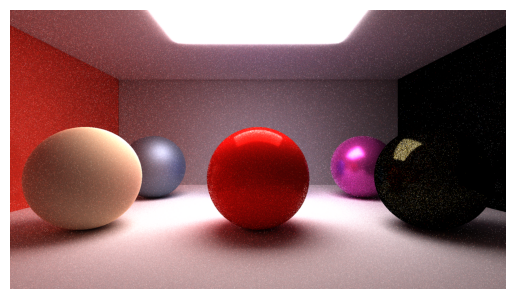

In [5]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg


def display_ppm(path):
    img = mpimg.imread(path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

display_ppm("analysis_1finalRender")


In [3]:
def interpret_analysis_file(path):
    with open(path, "r") as f:
        line = f.readline()
        SAMPLE_INDEX_DATA = []
        SPP_GAP_DATA = []
        while line != "":
   
            line = line.strip().split()
            if line and line[0].isnumeric():
                    
                SAMPLE_INDEX_DATA.append(int(line[0]))
                SPP_GAP_DATA.append(float(line[1]))
            elif line[0] == "DONE":
                line = f.readline()
                break
            line = f.readline()

    

        SPP_FINAL_DIFF_DATA = []
        while line != "":
            line = line.strip().split()
            if line and line[0].isnumeric():
                SPP_FINAL_DIFF_DATA.append(float(line[1]))
            
            line = f.readline()
        
        return [SAMPLE_INDEX_DATA, SPP_GAP_DATA, SPP_FINAL_DIFF_DATA]



In [1]:
import PathTracerPy as pt 

pt.cvsample(500, 10, "analysis_1")


----ANALYSIS BEGUN---
----------------------
 PROGRESS 0.2%
COMPUTED RENDER
COMPUTED SSE: 113.48
----------------------
 PROGRESS 0.4%
COMPUTED RENDER
COMPUTED SSE: 337394
----------------------
 PROGRESS 0.6%
COMPUTED RENDER
COMPUTED SSE: 21211.8
----------------------
 PROGRESS 0.8%
COMPUTED RENDER
COMPUTED SSE: 7628.29
----------------------
 PROGRESS 1%
COMPUTED RENDER
COMPUTED SSE: 3404.68
----------------------
 PROGRESS 1.2%
COMPUTED RENDER
COMPUTED SSE: 1862.23
----------------------
 PROGRESS 1.4%
COMPUTED RENDER
COMPUTED SSE: 1022.74
----------------------
 PROGRESS 1.6%
COMPUTED RENDER
COMPUTED SSE: 609.697
----------------------
 PROGRESS 1.8%
COMPUTED RENDER
COMPUTED SSE: 377.579
----------------------
 PROGRESS 2%
COMPUTED RENDER
COMPUTED SSE: 280.25
----------------------
 PROGRESS 2.2%
COMPUTED RENDER
COMPUTED SSE: 212.744
----------------------
 PROGRESS 2.4%
COMPUTED RENDER
COMPUTED SSE: 198.766
----------------------
 PROGRESS 2.6%
COMPUTED RENDER
COMPUTED SSE: 96.93

[]

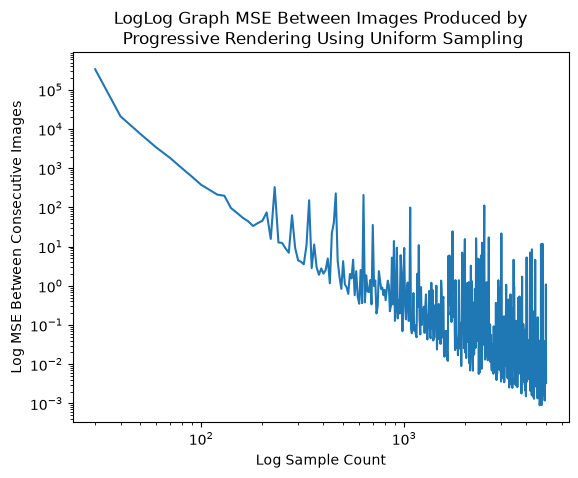

In [ ]:
data = interpret_analysis_file("analysis_1")


import matplotlib.pyplot as plt
import numpy as np

plt.title("LogLog Graph MSE Between Images Produced by\n Progressive Rendering Using Uniform Sampling")


slope, intercept = np.polyfit(np.log(data[0][1:]), np.log(data[1][1:]), 1)


smoothed_data = []
for i in range(int(len(data[0])/10)):
    curr_index = i*10
    last_index = min(len(data[1]), i+10)
    for k in range(10):
        smoothed_data.append(sum(data[1][curr_index:last_index])/(last_index - curr_index))

plt.xlabel("Log Sample Count")
plt.ylabel("Log MSE Between Consecutive Images")
plt.loglog(data[0][1:], data[1][1:])
plt.loglog()

plt.plot(data[0][1:], slope * data[0][1] + intercp)

